# 02 — Topic Deep Dive

> **Which discovered complaint topics concentrate risk, and where should remediation start?**

| | |
|---|---|
| **Audience** | Operations leads, product owners, compliance analysts |
| **Owner** | CX Complaint Intelligence team |
| **Status** | Reference implementation (portfolio sample) |
| **Last reviewed** | 2026-05-25 |
| **Runtime** | ~10 s on the bundled sample |
| **Reproduces from** | `reports/sample/complaint_scores.csv + reports/sample/topic_terms.csv` |

## Business question

Which complaint topics from the NMF baseline carry the highest risk concentration, and what representative complaints support the case for intervention?

## How to read this notebook

1. Section **0** initialises the environment and loads data.
2. Sections **1-N** build the analysis tables and visuals.
3. The **Insights** section is generated from the computed tables &mdash; it does not contain hand-written claims.
4. The **Limitations** section flags known caveats before stakeholders act on the numbers.
5. The **Exports** section persists every table and figure under `reports/notebook/02/` so the output is auditable.


## 0. Setup

This cell:

- locates the project root from wherever the kernel was started;
- applies the shared matplotlib house style and pandas display options;
- creates the artefact directory `reports/notebook/02/`;
- captures the Python and library versions used for this run.


In [1]:
from __future__ import annotations

import warnings
from IPython.display import Markdown, display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cx_complaints.reports.notebook_utils import (
    PALETTE,
    RISK_COLORS,
    concentration_table,
    horizontal_bar,
    kpi_table,
    load_complaints,
    load_pipeline_outputs,
    monthly_summary,
    render_environment,
    save_figure,
    save_table,
    setup_notebook,
    topic_labels,
    write_environment_snapshot,
)

warnings.filterwarnings("ignore", category=FutureWarning)

ctx = setup_notebook("02")
render_environment(ctx)


,field,value
0,python,3.12.11
1,platform,Windows-11-10.0.26200-SP0
2,numpy,2.4.6
3,pandas,2.3.3
4,matplotlib,3.10.9
5,scikit-learn,1.8.0
6,project_root,C:\Users\diogo\work_code\portfolio\cx-complain...
7,notebook_id,02


## 1. Load pipeline outputs

In [2]:
scores, topic_terms = load_pipeline_outputs(ctx)
scores = scores.dropna(subset=["topic_id"]).copy()
scores["topic_id"] = scores["topic_id"].astype(int)
print(f"Scored complaints: {len(scores):,}")
print(f"Topics discovered: {scores['topic_id'].nunique()}")
labels = topic_labels(topic_terms, top_n=6)
labels

Scored complaints: 1,000
Topics discovered: 8


,topic_id,topic_label
0,0,"redacted, redacted redacted, money, account, b..."
1,1,"consumer, 15, section, states, 1681, consumer ..."
2,2,"accounts, fcra 605b, significance eliminating,..."
3,3,"payment, late, payments, creditor, late paymen..."
4,4,"credit, report, credit report, information, ac..."
5,5,"payments, perplexing discover, perplexing, upd..."
6,6,"letters, party involved, really sure, falsely ..."
7,7,"consumer reports, consent, consumer, reports, ..."


## 2. Topic summary cards

In [3]:
topic_summary = (
    scores.groupby("topic_id", as_index=False)
    .agg(
        complaints=("complaint_id", "size"),
        avg_risk=("risk_score", "mean"),
        high_risk_share_pct=("risk_level", lambda s: (s == "high").mean() * 100),
    )
    .merge(labels, on="topic_id", how="left")
    .sort_values(["high_risk_share_pct", "complaints"], ascending=[False, False])
)
topic_summary["avg_risk"] = topic_summary["avg_risk"].round(2)
topic_summary["high_risk_share_pct"] = topic_summary["high_risk_share_pct"].round(1)
topic_summary

,topic_id,complaints,avg_risk,high_risk_share_pct,topic_label
3,3,66,3.88,36.40,"payment, late, payments, creditor, late paymen..."
0,0,329,3.66,21.60,"redacted, redacted redacted, money, account, b..."
7,7,52,3.56,11.50,"consumer reports, consent, consumer, reports, ..."
4,4,410,3.40,7.80,"credit, report, credit report, information, ac..."
5,5,20,2.48,5.00,"payments, perplexing discover, perplexing, upd..."
1,1,63,2.91,3.20,"consumer, 15, section, states, 1681, consumer ..."
2,2,39,3.16,0.00,"accounts, fcra 605b, significance eliminating,..."
6,6,21,2.82,0.00,"letters, party involved, really sure, falsely ..."


## 3. Topic volume vs. risk concentration

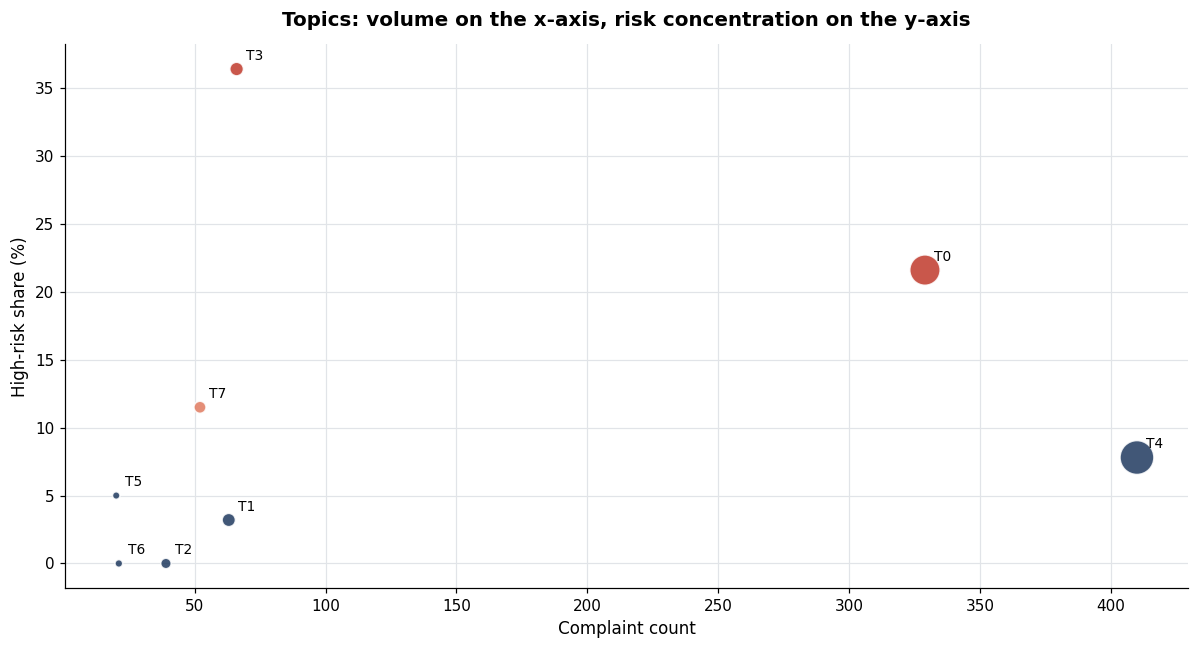

In [4]:
fig, ax = plt.subplots(figsize=(11, 6))
colors = [
    PALETTE["warning"] if share >= 20 else PALETTE["accent"] if share >= 10 else PALETTE["primary"]
    for share in topic_summary["high_risk_share_pct"]
]
ax.scatter(
    topic_summary["complaints"], topic_summary["high_risk_share_pct"],
    s=topic_summary["complaints"] * 1.2,
    color=colors, edgecolor="white", linewidth=1.0, alpha=0.85,
)
for _, row in topic_summary.iterrows():
    ax.annotate(
        f"T{int(row['topic_id'])}",
        (row["complaints"], row["high_risk_share_pct"]),
        xytext=(6, 6), textcoords="offset points", fontsize=9,
    )
ax.set_title("Topics: volume on the x-axis, risk concentration on the y-axis")
ax.set_xlabel("Complaint count")
ax.set_ylabel("High-risk share (%)")
fig.tight_layout()
save_figure(ctx, fig, "topic_volume_vs_risk")
plt.show()

## 4. Representative complaints for top-risk topics

The three topics with the largest high-risk share are surfaced with their three highest-scoring complaints. Narratives are truncated for readability.

In [5]:
focus_topic_ids = (
    topic_summary.sort_values(["high_risk_share_pct", "complaints"], ascending=False)
    .head(3)["topic_id"].tolist()
)
samples = scores[scores["topic_id"].isin(focus_topic_ids)].copy()
samples = samples.sort_values(["topic_id", "risk_score"], ascending=[True, False])
samples["narrative_preview"] = (
    samples["complaint_what_happened"].fillna("").astype(str).str.slice(0, 220) + "…"
)
preview = (
    samples[[
        "topic_id", "risk_score", "product", "issue", "company", "narrative_preview",
    ]]
    .groupby("topic_id")
    .head(3)
    .merge(labels, on="topic_id", how="left")
)
preview

,topic_id,risk_score,product,issue,company,narrative_preview,topic_label
0,0,7.00,Credit reporting or other personal consumer re...,Incorrect information on your report,"EQUIFAX, INC.",XXXX XXXX has reported my mortgage late 150 da...,"redacted, redacted redacted, money, account, b..."
1,0,7.00,Mortgage,Struggling to pay mortgage,Fairway Independent Mortgage Corporation,Dear XXXX ; to start thank for give me the tim...,"redacted, redacted redacted, money, account, b..."
2,0,7.00,Credit reporting or other personal consumer re...,Incorrect information on your report,"TRANSUNION INTERMEDIATE HOLDINGS, INC.","XXXX I XXXX XXXX XXXX XXXX XXXX, XXXX Pennsylv...","redacted, redacted redacted, money, account, b..."
3,3,6.25,Credit reporting or other personal consumer re...,Incorrect information on your report,SYNCHRONY FINANCIAL,I am writing to dispute the following informat...,"payment, late, payments, creditor, late paymen..."
4,3,5.75,Credit reporting or other personal consumer re...,Incorrect information on your report,"EQUIFAX, INC.",My accounts was never late! I have had excepti...,"payment, late, payments, creditor, late paymen..."
5,3,5.75,Credit reporting or other personal consumer re...,Incorrect information on your report,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",My account with XXXX XXXX XXXX was never late!...,"payment, late, payments, creditor, late paymen..."
6,7,5.50,Credit reporting or other personal consumer re...,Improper use of your report,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",The account in regards to XXXX XXXXXXXX XXXX t...,"consumer reports, consent, consumer, reports, ..."
7,7,5.00,Credit reporting or other personal consumer re...,Incorrect information on your report,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",""" The Fair Credit Reporting Act ( 15 U.S. Code...","consumer reports, consent, consumer, reports, ..."
8,7,5.00,Credit reporting or other personal consumer re...,Incorrect information on your report,"EQUIFAX, INC.",""" The Fair Credit Reporting Act ( XXXX XXXX Co...","consumer reports, consent, consumer, reports, ..."


## 5. Insights

In [6]:
top_focus = topic_summary.head(1).iloc[0]
biggest_topic = topic_summary.sort_values("complaints", ascending=False).iloc[0]
narrative = "\n".join([
    f"- **Highest-risk topic**: Topic {int(top_focus['topic_id'])} ({top_focus['topic_label']}) "
    f"with a high-risk share of **{top_focus['high_risk_share_pct']:.1f}%** "
    f"across {int(top_focus['complaints'])} complaints.",
    f"- **Largest-volume topic**: Topic {int(biggest_topic['topic_id'])} "
    f"({biggest_topic['topic_label']}) covering {int(biggest_topic['complaints'])} complaints "
    "&mdash; the broadest CX surface area.",
    "- **Recommendation**: pair the highest-risk topic with notebook 08 to build a priority "
    "review queue, and watch the largest-volume topic in notebook 06 to detect early acceleration.",
])
display(Markdown(narrative))

- **Highest-risk topic**: Topic 3 (payment, late, payments, creditor, late payment, error) with a high-risk share of **36.4%** across 66 complaints.
- **Largest-volume topic**: Topic 4 (credit, report, credit report, information, accounts, account) covering 410 complaints &mdash; the broadest CX surface area.
- **Recommendation**: pair the highest-risk topic with notebook 08 to build a priority review queue, and watch the largest-volume topic in notebook 06 to detect early acceleration.

## Limitations

- The risk score is heuristic, not a legal or regulatory finding. It exists to triage analyst attention.
- CFPB narratives are only published when the consumer consents, so coverage is partial.
- Company-level comparisons mix companies of very different sizes &mdash; always pair them with volume context.
- The sample bundled with this repo is a small subset of the public CFPB dataset and is meant for demonstration, not production decisions.

## Exports

All tables and figures generated above are saved under `reports/notebook/02/`. The environment snapshot is written alongside so a reader can reproduce the run.


In [7]:
save_table(ctx, topic_summary, "topic_summary")
save_table(ctx, preview, "topic_representative_samples")
write_environment_snapshot(ctx)
sorted(ctx.artefact_dir.iterdir())

[WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/02/environment.json'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/02/topic_representative_samples.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/02/topic_summary.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/02/topic_volume_vs_risk.png')]